# 11 — Next-interval direction vs. volatility-adjusted targets

**Development-only experiment.** Compare three label definitions using **five expanding chronological folds**. The newest **20% of timestamps is locked away**. No random train/test splitting. No random forests, regressors or neural networks.

**Interpretation:** Accuracy across *different targets* is **not directly comparable**; use target-specific prior baselines, balanced accuracy, ROC-AUC, class prevalence and confusion matrices. Volatility-adjusted labels use the **current bar's trailing 20-bar volatility**, never next-bar volatility. Binary classification excludes exactly zero next returns.


In [1]:
from pathlib import Path
import sys
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
if not (ROOT / 'src' / 'stock_ml_dynamic').exists():
    raise FileNotFoundError(f'Run from the repository root or notebooks directory: {ROOT}')
sys.path.insert(0, str(ROOT / 'src'))
from stock_ml_dynamic.pooled_models import load_master
from stock_ml_dynamic.target_diagnostics import (run_target_diagnostics, summary_targets, plot_target_diagnostics)

candidates = [ROOT / 'artifacts/master_tables/1d', ROOT / 'notebooks/artifacts/master_tables/1d']
required = ('master_labeled.parquet','latest_inference.parquet','transformers.joblib','manifest.json')
master_dir = next((p for p in candidates if all((p / f).exists() for f in required)), None)
if master_dir is None:
    raise FileNotFoundError('Master artifacts not found. Run Notebook 03 first. Checked: ' + ', '.join(map(str,candidates)))
master, latest, bundle, manifest = load_master(master_dir)
print('Master directory:',master_dir)
print('Master rows:',len(master),'symbols:',master.symbol.nunique())


Master directory: /home/oem/Documents/github/stock_ml_dynamic/notebooks/artifacts/master_tables/1d
Master rows: 431271 symbols: 220


In [2]:
# Main experiment: 5 folds × 3 targets × 3 models = 45 fits.
# Each fold re-fits the target cutoffs (where applicable), K-means,
# original feature preprocessing, and added-feature scaler using training data only.
OUTPUT = ROOT / 'artifacts/target_diagnostics/1d'
N_FOLDS = 5
MAX_TRAIN_ROWS = 120_000
VOLATILITY_MULTIPLIER = 0.5   # Fixed in advance; do not tune against final holdout

scores, roc, prevalence, confusion, eligibility, holdout_boundary = run_target_diagnostics(
    master, n_folds=N_FOLDS, holdout_fraction=0.20,
    max_train_rows=MAX_TRAIN_ROWS, selected_k=4, cluster_fit_limit=15_000,
    volatility_multiplier=VOLATILITY_MULTIPLIER, output_dir=OUTPUT,
)
print('Locked development boundary:',holdout_boundary)
print('Holdout status: NOT EVALUATED')


Fold 1/5: train=180,377 test=30,814 preprocess=9.0s
  tertiles             prior_baseline  acc=0.3470 auc=0.5000 fit=0.0s
  tertiles             logistic_l2     acc=0.3598 auc=0.5380 fit=6.1s
  tertiles             logistic_l1     acc=0.3616 auc=0.5411 fit=30.7s
  volatility_adjusted  prior_baseline  acc=0.4196 auc=0.5000 fit=0.0s
  volatility_adjusted  logistic_l2     acc=0.4086 auc=0.5214 fit=5.4s
  volatility_adjusted  logistic_l1     acc=0.4083 auc=0.5254 fit=34.4s
  binary_direction     prior_baseline  acc=0.5003 auc=0.5000 fit=0.0s
  binary_direction     logistic_l2     acc=0.4750 auc=0.4767 fit=1.9s
  binary_direction     logistic_l1     acc=0.4742 auc=0.4779 fit=19.9s
Fold 2/5: train=211,408 test=31,031 preprocess=10.2s
  tertiles             prior_baseline  acc=0.3180 auc=0.5000 fit=0.0s
  tertiles             logistic_l2     acc=0.4028 auc=0.5755 fit=6.5s
  tertiles             logistic_l1     acc=0.4001 auc=0.5730 fit=20.1s
  volatility_adjusted  prior_baseline  acc=0.4245 a

In [3]:
summary = summary_targets(scores)
display(summary)
display(scores[['fold','target','model','accuracy','balanced_accuracy','roc_auc','log_loss','fit_seconds']])


,target,model,accuracy,accuracy_sd,balanced_accuracy,auc,auc_sd,log_loss,fit_seconds,predict_seconds
1,binary_direction,logistic_l2,0.515039,0.022622,0.505122,0.507534,0.022821,0.699054,9.539874,0.081574
0,binary_direction,logistic_l1,0.513737,0.022326,0.502683,0.505469,0.019872,0.697494,84.400934,0.029029
2,binary_direction,prior_baseline,0.523022,0.015685,0.500000,0.500000,0.000000,0.692150,0.088528,0.002348
3,tertiles,logistic_l1,0.395078,0.023068,0.383255,0.558356,0.012301,1.087658,116.261874,0.049325
4,tertiles,logistic_l2,0.393731,0.022988,0.382636,0.557457,0.013959,1.089582,24.410789,0.113824
5,tertiles,prior_baseline,0.315377,0.022844,0.333333,0.500000,0.000000,1.098725,0.088914,0.002663
6,volatility_adjusted,logistic_l1,0.425295,0.010511,0.351049,0.542116,0.011746,1.076318,146.485403,0.048093
7,volatility_adjusted,logistic_l2,0.423591,0.008650,0.352733,0.541749,0.013977,1.078109,30.244467,0.090839
8,volatility_adjusted,prior_baseline,0.430847,0.010033,0.333333,0.500000,0.000000,1.077331,0.094650,0.002869


,fold,target,model,accuracy,balanced_accuracy,roc_auc,log_loss,fit_seconds
0,1,tertiles,prior_baseline,0.346953,0.333333,0.500000,1.098594,0.015389
1,1,tertiles,logistic_l2,0.359804,0.364813,0.538027,1.103722,6.094744
2,1,tertiles,logistic_l1,0.361589,0.367490,0.541059,1.098107,30.671804
3,1,volatility_adjusted,prior_baseline,0.419647,0.333333,0.500000,1.083988,0.019150
4,1,volatility_adjusted,logistic_l2,0.408645,0.343545,0.521363,1.101162,5.390151
5,1,volatility_adjusted,logistic_l1,0.408288,0.341739,0.525389,1.095327,34.406739
6,1,binary_direction,prior_baseline,0.500343,0.500000,0.500000,0.694647,0.017978
7,1,binary_direction,logistic_l2,0.475016,0.474868,0.476678,0.714221,1.927009
8,1,binary_direction,logistic_l1,0.474232,0.474066,0.477898,0.709517,19.902290
9,2,tertiles,prior_baseline,0.318005,0.333333,0.500000,1.098766,0.021363


In [4]:
display(prevalence.pivot_table(index=['fold','target'],columns='class_id',values='test_share'))
display(confusion.groupby(['target','model','actual','predicted'],as_index=False)['count'].sum().head(45))
print('Binary zero-return exclusions (test):')
display(scores[scores.target.eq('binary_direction')].groupby('fold',as_index=False).zero_test_excluded.max())


class_id                         0         1         2
fold target                                           
1    binary_direction     0.499657  0.500343       NaN
     tertiles             0.264750  0.346953  0.388298
     volatility_adjusted  0.419647  0.290907  0.289446
2    binary_direction     0.472508  0.527492       NaN
     tertiles             0.361026  0.320969  0.318005
     volatility_adjusted  0.424479  0.309594  0.265928
3    binary_direction     0.477048  0.522952       NaN
     tertiles             0.399762  0.293126  0.307112
     volatility_adjusted  0.437466  0.296574  0.265960
4    binary_direction     0.455951  0.544049       NaN
     tertiles             0.390981  0.315695  0.293324
     volatility_adjusted  0.444473  0.308195  0.247332
5    binary_direction     0.479727  0.520273       NaN
     tertiles             0.338921  0.325478  0.335600
     volatility_adjusted  0.428170  0.298975  0.272855

,target,model,actual,predicted,count
0,binary_direction,logistic_l1,0,0,19080
1,binary_direction,logistic_l1,0,1,54581
2,binary_direction,logistic_l1,1,0,20509
3,binary_direction,logistic_l1,1,1,60276
4,binary_direction,logistic_l2,0,0,21231
5,binary_direction,logistic_l2,0,1,52430
6,binary_direction,logistic_l2,1,0,22459
7,binary_direction,logistic_l2,1,1,58326
8,binary_direction,prior_baseline,0,0,0
9,binary_direction,prior_baseline,0,1,73661


Binary zero-return exclusions (test):


,fold,zero_test_excluded
0,1,175
1,2,204
2,3,227
3,4,224
4,5,118


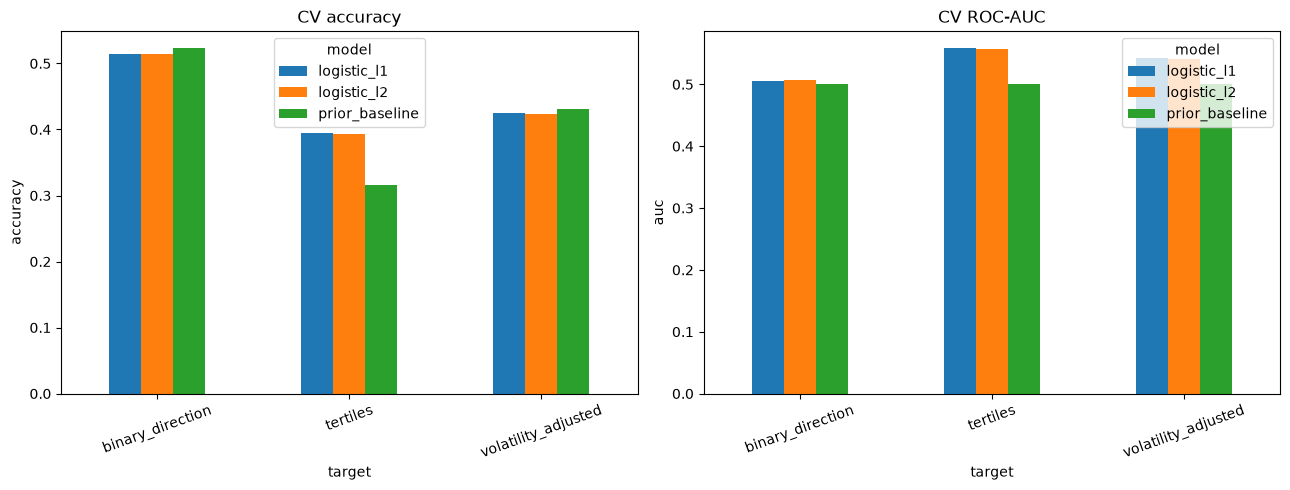

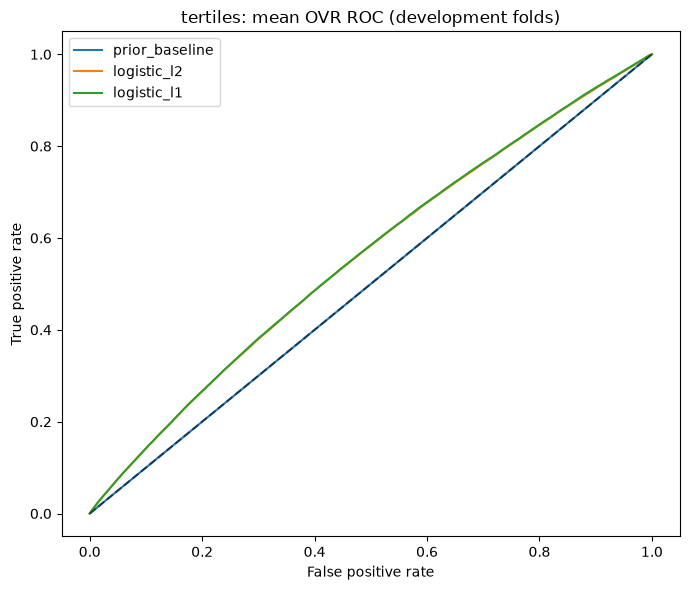

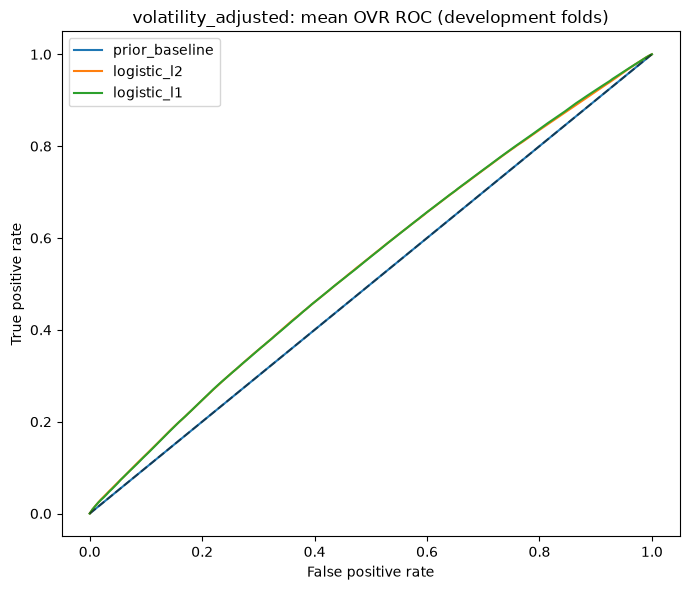

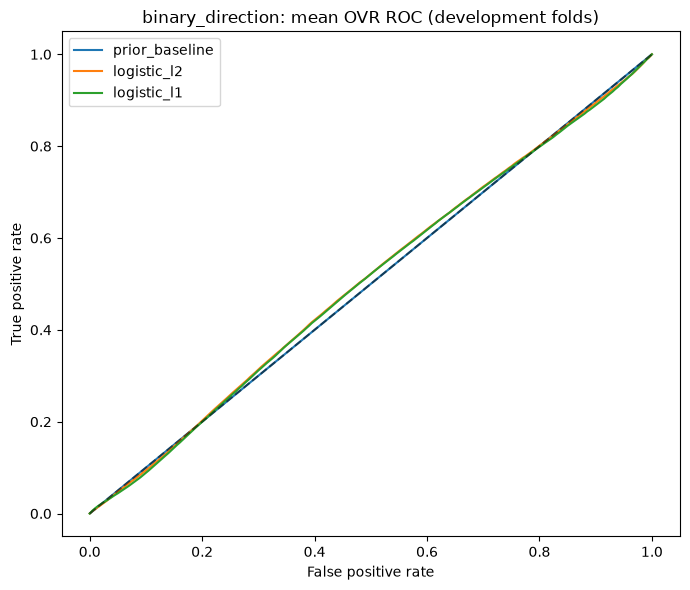

Saved results to: /home/oem/Documents/github/stock_ml_dynamic/artifacts/target_diagnostics/1d


In [5]:
summary = plot_target_diagnostics(scores,roc,prevalence,OUTPUT)
print('Saved results to:',OUTPUT)


## Interpretation and next decision

- **Tertiles**: down=2, middle=0, up=1. Boundaries fitted to each fold's training next returns only.
- **Volatility-adjusted**: down if next return < −0.5 × *current* trailing 20-bar return volatility; up if > +0.5 × volatility; otherwise neutral.
- **Binary**: down=0, up=1; exact zero returns excluded (counts reported).
- Compare each model to its **own target's baseline** and inspect fold-to-fold stability. A higher binary accuracy does not necessarily mean a more profitable or more informative model.
- No final holdout results are generated. Keep that period untouched until the target and model are frozen.
